# Round 4 — results

**Question.** Same as round 3 — what does aligning **which layers**, at **which timesteps**, and **how strongly** do to a recurrent student — but now the target has a **different, larger architecture** than the students. Section 5 compares the two rounds directly.

**Models**
- **Target**: DyRCNNx8 (two convolutions per area, 5.6 M parameters), trained on the ground-truth Imagenette labels with the DynVision paper's default (Table 1) recipe. **Feedback connections are off** in this recipe.
- **Students**: DyRCNNx4 (one convolution per area, 0.5 M parameters), **identical to round 3**: same architecture (with feedback), recipe, initial weights and batch order. They are trained on the target's final time-step predictions (pseudo-labels) with
  `loss = CE + Σ weight × log(1 − CKA(student layer, target layer))`.

So between rounds 3 and 4 **only the target changes**; every round 4 student has a round 3 twin with the same condition and seed.

| Condition | Alignment term(s) | Total CKA weight |
|---|---|---|
| Control | none (CE only) | 0 |
| IT, w=1 | IT at t19 | 1.0 |
| IT, w=0.1 | IT at t19 | 0.1 |
| V1+V4+IT, 0.1 each | V1, V4, IT at t19 | 0.3 |
| V1+V4+IT, 0.1 total | V1, V4, IT at t19, 0.033 each | 0.1 |
| IT at 4 timesteps, 0.1 total | IT at t2, t6, t12, t19, 0.025 each | 0.1 |

Each condition is trained with **3 seeds** (2723, 2724, 2725). Within a seed, all conditions start from the same weights and see the same batches in the same order, so they differ only in the loss (paired design).

**How the figures show the seeds.** Thick line = mean over the 3 seeds; thin faint lines = the individual seeds. Every condition has the same color in every figure.

**Two kinds of x-axis**
- *Epochs completed* (training curves, validation set): **0 = before training**, 1 = after the first epoch, …, 200 = end.
- *Timestep* (test set, 3,925 images never used for training): the network sees the same image at every one of the 20 timesteps (0–19); every quantity is measured at each timestep. Grey shading = timesteps 0–3, which are not in the students' CE loss.

**CKA** is always linear CKA (biased estimator) between the student's and the target's activations of the same area at the same timestep. Each area's response is read out after the area's nonlinearity and before pooling, and flattened (channels × height × width); CKA compares the image-by-image similarity structure, so the two models' feature sizes do not need to match. On the test set it is computed over all 3,925 images at once; during training it is averaged over batches of 32 images (higher than the full-set value).

**Sections**: 0 Target · 1 Summary table · 2 Which layers · 3 Which timesteps · 4 How strongly · 5 Round 3 vs round 4 · Appendix: training

## Model configuration and its time course

**Target vs students.** Both have four areas **V1 → V2 → V4 → IT** followed by a classifier, with skip connections V1→V4 and V2→IT and the same time constant and delays. They differ inside each area and in feedback:

| | Students (= round 3 target and students) | Round 4 target |
|---|---|---|
| Model | DyRCNNx4 | DyRCNNx8 |
| Parameters | 506,012 | 5,611,312 |
| Convolutions per area | 1 | 2 (conv → ReLU → conv) |
| Channels V1 / V2 / V4 / IT | 36 / 64 / 121 / 256 | 64 / 144 / 256 / 529 |
| Map size V1 / V4 / IT | 224 / 56 / 28 | 112 / 7 / 4 |
| Features per image V1 / V4 / IT | 1.81 M / 379 K / 201 K | 803 K / 12.5 K / 8.5 K |
| IT receptive field | ~29 px | ~345 px |
| **Feedback (V4→V1, IT→V2)** | **on** (12 ms delay) | **off** |
| Training labels | target's t19 predictions | ground truth |
| Optimizer, learning rate | AdamW (wd 0.01), 1.41e-4 | Adam (L2 5e-4), 8e-4 |
| Batch, gradient clipping | 32, 500 | 1024 (64 × 16), 1.0 |
| CE timesteps | t4–t19 | t0–t19 |
| Other | — | activity loss 0.0002, data augmentation (rotation, translation, flip, colour jitter) |

Timesteps (20), dt, tau, feedforward / skip / recurrence delays, recurrence type and epochs (200) are the same.

**Time is simulated in steps of dt = 2 ms.** Every delay is a multiple of dt, so a delay of *d* ms means the signal used at timestep *t* comes from timestep *t − d/2*.

| Parameter | Value | In timesteps | What it means | Effect on the time course |
|---|---|---|---|---|
| Time step `dt` | 2 ms | 1 step | Resolution of the simulation | 20 timesteps = 40 ms of simulated time |
| Time constant `tau` | 9 ms | — | How fast a unit's activity follows its input: each step it moves dt/tau ≈ 22% of the way to the new input (leaky integration) | Activity builds up gradually over the first steps even with no delays; this alone makes accuracy rise over t0–t3 |
| Feedforward delay `t_feedforward` | 0 ms | 0 steps | Time for the signal to go from one area to the next (V1→V2→V4→IT) | The image reaches IT at **t0**; depth adds no latency |
| Skip delay `t_skip` | 0 ms | 0 steps | Same, for V1→V4 and V2→IT | Present from **t0** |
| Recurrent delay `t_recurrence` | 6 ms | **3 steps** | Within-area (lateral) recurrence: an area receives **its own activity from 3 steps earlier** | No recurrent input at t0–t2; recurrence acts from **t3** on |
| Feedback delay `t_feedback` (students only) | 12 ms | **6 steps** | Top-down input: V1 receives **V4's activity from 6 steps earlier**, V2 receives IT's | No feedback at t0–t5; feedback acts from **t6** on. The target has no feedback at all |
| Students' CE loss window (`ce_first_timestep`) | t4–t19 | — | Timesteps whose output is trained on the label | t0–t3 (grey band in the figures) are free |

**Which inputs are active when**

| Timesteps | Students | Target |
|---|---|---|
| t0–t2 | feedforward + skip | feedforward + skip |
| t3–t5 | + within-area recurrence | + within-area recurrence |
| t6–t19 | + feedback (from 6 steps earlier) | no change (no feedback) |

From t6 on, the students' dynamics include a top-down pathway that the target does not have.

## Settings

In [1]:
DATA_DIR = "figure_data"              # round 4 tables + target model card
DATA_DIR_R3 = "figure_data_round3"    # round 3 tables (section 5 only)
SAVE_FIGURES = False                  # True: also write PNG + PDF of every figure
FIG_DIR = "figures"

In [2]:
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

# One color and one display name per condition -- used in EVERY figure.
# Change a color here and it changes everywhere.
COLORS = {
    "control":            "#e8743b",   # orange
    "IT_w1":              "#1f4e9c",   # dark blue
    "IT_w0p1":            "#5b9bd5",   # light blue
    "V1V4IT_w0p1":        "#2e7d32",   # dark green
    "V1V4IT_total0p1":    "#8bc34a",   # light green
    "IT_multiT_total0p1": "#8e44ad",   # purple
}
LABELS = {
    "control":            "Control (CE only)",
    "IT_w1":              "IT, w=1",
    "IT_w0p1":            "IT, w=0.1",
    "V1V4IT_w0p1":        "V1+V4+IT, 0.1 each",
    "V1V4IT_total0p1":    "V1+V4+IT, 0.1 total",
    "IT_multiT_total0p1": "IT at t2/6/12/19, 0.1 total",
}
ORDER = list(COLORS)
TARGET_COLOR = "#555555"
BASELINE_COLOR = "#c9c9c9"

T = 20               # timesteps 0..19
LAST_T = 19          # pseudo-labels and the usual alignment timestep
CE_FIRST_T = 4       # students' CE is computed on timesteps 4..19 (the target's on 0..19)
D_TIMESTEPS = [2, 6, 12, 19]   # timesteps aligned in "IT at t2/6/12/19"

# Section 5: the same condition color in both rounds; the round is shown by the marker / line style.
ROUND_STYLE = {
    "round 3": dict(marker="s", ls="--", filled=False, label="round 3 (x4 target)"),
    "round 4": dict(marker="o", ls="-", filled=True, label="round 4 (x8 target)"),
}


def save(fig, name):
    if SAVE_FIGURES:
        Path(FIG_DIR).mkdir(parents=True, exist_ok=True)
        fig.savefig(Path(FIG_DIR) / f"{name}.png", dpi=200, bbox_inches="tight")
        fig.savefig(Path(FIG_DIR) / f"{name}.pdf", bbox_inches="tight")

## Data tables

Built on burst from the raw outputs by `round4/build_figure_data.py` and shipped in `figure_data/`. `figure_data_round3/` holds the same five tables for round 3 (used only in section 5). Every figure below is drawn from these tables only.

| File | One row = | Columns |
|---|---|---|
| `target_training.csv` | target, one epoch | `epochs_completed`, `train_ce`, `val_ce`, `train_accuracy_eval` (every 10 epochs), `val_accuracy`, `val_acc_t00`…`val_acc_t19` |
| `student_training.csv` | student (condition, seed), one epoch | `val_ce`, `val_total_loss`, `val_same_answer_as_target`, `val_accuracy`, `val_cka_<layer>_t<tt>` (batch CKA), `grad_ce`, `grad_cka_sum`, `grad_cka_<layer>_t<tt>`, `grad_ratio_cka_to_ce`, `train_grad_norm`, `train_clip_fraction`, `learning_rate` |
| `test_behavior.csv` | model, one timestep (test set) | `model`, `condition`, `seed`, `timestep`, `accuracy`, `same_answer_as_target`, `ce_vs_target_answer` |
| `test_cka.csv` | comparison, layer, timestep (test set) | `comparison` (`student_vs_target` or `control_vs_control`), `condition`, `seed`, `other_seed`, `layer`, `timestep`, `cka` |
| `summary.csv` | condition × seed, timestep 19 (test set) | `accuracy`, `same_answer_as_target`, `ce_vs_target_answer`, `cka_V1`, `cka_V4`, `cka_IT` |

Definitions
- `accuracy`: fraction of images whose predicted class is the true class.
- `same_answer_as_target`: fraction of images whose predicted class equals the **target's final (t19) prediction** — the label the students were trained on. For the target itself it shows how often its earlier timesteps already give its final answer.
- `ce_vs_target_answer`: cross-entropy with respect to that same label.
- `control_vs_control`: CKA between the controls of two different seeds — how similar two students are anyway when only the random seed differs (baseline for the CKA figures).
- `train_ce` (target): mean training loss during each epoch; at epoch 0 the loss of the initial weights on the training set.
- `grad_*`: once per epoch on a fixed batch of 32 training images: the norm of the gradient of each loss term (with its weight); `grad_ratio_cka_to_ce` = |sum of CKA-term gradients| / |CE gradient| (> 1: the alignment terms dominate the update).

In [3]:
# Read the tables (every figure below uses only these).
data = Path(DATA_DIR)
target_training = pd.read_csv(data / "target_training.csv")
student_training = pd.read_csv(data / "student_training.csv")
test_behavior = pd.read_csv(data / "test_behavior.csv")
test_cka = pd.read_csv(data / "test_cka.csv")
summary = pd.read_csv(data / "summary.csv")

# Round 3 (section 5 only)
data_r3 = Path(DATA_DIR_R3)
test_behavior_r3 = pd.read_csv(data_r3 / "test_behavior.csv")
test_cka_r3 = pd.read_csv(data_r3 / "test_cka.csv")
summary_r3 = pd.read_csv(data_r3 / "summary.csv")
ROUNDS = {"round 3": dict(summary=summary_r3, test_cka=test_cka_r3, test_behavior=test_behavior_r3),
          "round 4": dict(summary=summary, test_cka=test_cka, test_behavior=test_behavior)}

try:
    import yaml
    target_card = yaml.safe_load((data / "target_model_card.yaml").read_text())
    TARGET_BEST_EPOCH = target_card["checkpoints"]["best.pt"]["epoch"] + 1   # in epochs completed
except Exception as exc:                                                     # pyyaml missing, or no card
    target_card, TARGET_BEST_EPOCH = None, None
    print("target model card not read:", exc)

print("seeds per condition:", student_training.groupby("condition")["seed"].nunique().to_dict())
print("epoch 0 (before training) present:", bool((student_training["epochs_completed"] == 0).any()))
print("target best checkpoint (epochs completed):", TARGET_BEST_EPOCH)
print("round 3 tables:", {k: len(v) for k, v in [("summary", summary_r3), ("test_cka", test_cka_r3)]})

seeds per condition: {'IT_multiT_total0p1': 3, 'IT_w0p1': 3, 'IT_w1': 3, 'V1V4IT_total0p1': 3, 'V1V4IT_w0p1': 3, 'control': 3}
epoch 0 (before training) present: True
target best checkpoint (epochs completed): 145
round 3 tables: {'summary': 19, 'test_cka': 1260}


## 0 — The target

The students learn the target's predictions and are aligned to its activity, so everything below is relative to this network. Its full configuration is in `target_model_card.yaml`.

### Figure 0.1 — Target: training and validation loss

- **Question**: did the target train normally, and is the checkpoint used as the target a sensible one?
- **Plotted**: `target_training.csv` — `train_ce` (dashed) and `val_ce` (solid) vs `epochs_completed`. Vertical line: the checkpoint used as the target (lowest validation loss).
- **How to read**: a validation curve that flattens while the training curve keeps falling = the target starts fitting its training images specifically. The training loss is measured on **augmented** training batches (rotation, translation, flip, colour jitter) while the network trains, so it is not directly comparable with the validation loss; Figure 0.2 compares the two on un-augmented images.

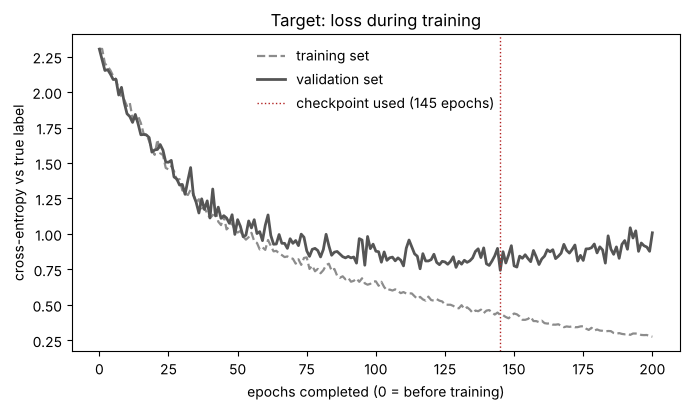

In [4]:
d = target_training
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(d["epochs_completed"], d["train_ce"], color="#8c8c8c", lw=1.6, ls="--", label="training set")
ax.plot(d["epochs_completed"], d["val_ce"], color=TARGET_COLOR, lw=2, label="validation set")
if TARGET_BEST_EPOCH is not None:
    ax.axvline(TARGET_BEST_EPOCH, color="#b22222", lw=1, ls=":", label=f"checkpoint used ({TARGET_BEST_EPOCH} epochs)")
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("cross-entropy vs true label")
ax.set_title("Target: loss during training")
ax.legend(frameon=False)
plt.tight_layout()
save(fig, "fig0_1_target_loss")
plt.show()

Findings: _to be written._

### Figure 0.2 — Target: accuracy on training vs validation images

- **Question**: how much does the target memorize its training images?
- **Plotted**: `target_training.csv` — `train_accuracy_eval` (dots, measured every 10 epochs) and `val_accuracy` vs `epochs_completed`; prediction at t19.
- **How to read**: the gap between the two = memorization. It matters because the students are trained on the same training images: the larger the gap, the closer the target's answers on those images are to the true labels.

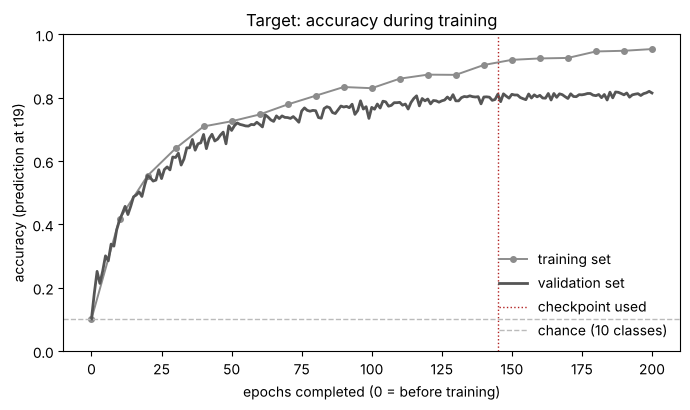

In [5]:
d = target_training
tr = d.dropna(subset=["train_accuracy_eval"])
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(tr["epochs_completed"], tr["train_accuracy_eval"], color="#8c8c8c", lw=1.4, marker="o", ms=4, label="training set")
ax.plot(d["epochs_completed"], d["val_accuracy"], color=TARGET_COLOR, lw=2, label="validation set")
if TARGET_BEST_EPOCH is not None:
    ax.axvline(TARGET_BEST_EPOCH, color="#b22222", lw=1, ls=":", label="checkpoint used")
ax.axhline(0.1, color="#bbbbbb", lw=1, ls="--", label="chance (10 classes)")
ax.set_ylim(0, 1)
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("accuracy (prediction at t19)")
ax.set_title("Target: accuracy during training")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
save(fig, "fig0_2_target_accuracy")
plt.show()

Findings: _to be written._

### Figure 0.3 — Target: accuracy at each timestep (test set)

- **Question**: how does the target's recognition develop over the 20 timesteps of one image presentation?
- **Plotted**: `test_behavior.csv`, `model == "target"` — `accuracy` vs `timestep`.
- **How to read**: the recurrent dynamics at work — how fast the target reaches its final answer. Its answer at t19 is the label the students learn. The target's CE covered all timesteps (t0–t19), so there is no grey band here.

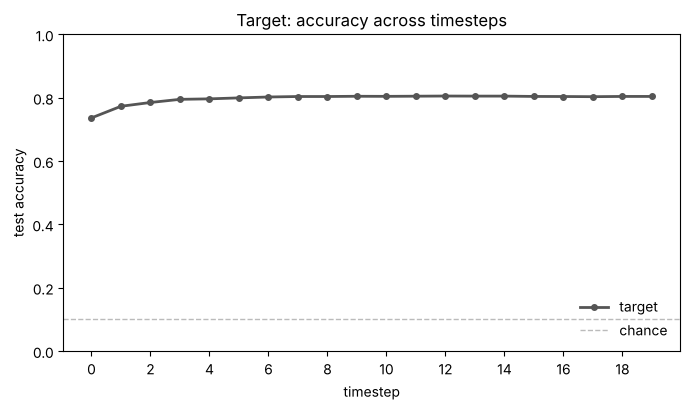

In [6]:
d = test_behavior[test_behavior["model"] == "target"]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(d["timestep"], d["accuracy"], color=TARGET_COLOR, lw=2, marker="o", ms=4, label="target")
ax.axhline(0.1, color="#bbbbbb", lw=1, ls="--", label="chance")
ax.set_ylim(0, 1)
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel("test accuracy")
ax.set_title("Target: accuracy across timesteps")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
save(fig, "fig0_3_target_accuracy_by_timestep")
plt.show()

Findings: _to be written._

## 1 — Summary table (test set, timestep 19)

Mean ± standard deviation over the 3 seeds. Source: `summary.csv`.

In [7]:
cols = ["accuracy", "same_answer_as_target", "ce_vs_target_answer", "cka_V1", "cka_V4", "cka_IT"]
s = summary[summary["condition"] != "target"]
mean = s.groupby("condition")[cols].mean().reindex(ORDER)
std = s.groupby("condition")[cols].std().reindex(ORDER)
table = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)
table.index = [LABELS[c] for c in table.index]
target_acc = summary.loc[summary["condition"] == "target", "accuracy"]
print(f"Target accuracy at t19: {target_acc.iloc[0]:.3f}" if len(target_acc) else "")
table

Target accuracy at t19: 0.804


,accuracy,same_answer_as_target,ce_vs_target_answer,cka_V1,cka_V4,cka_IT
Control (CE only),0.77 ± 0.003,0.794 ± 0.005,0.743 ± 0.014,0.765 ± 0.039,0.546 ± 0.06,0.346 ± 0.006
"IT, w=1",0.754 ± 0.003,0.785 ± 0.004,0.665 ± 0.011,0.798 ± 0.046,0.605 ± 0.104,0.755 ± 0.005
"IT, w=0.1",0.77 ± 0.005,0.801 ± 0.0,0.714 ± 0.013,0.759 ± 0.01,0.613 ± 0.017,0.64 ± 0.002
"V1+V4+IT, 0.1 each",0.758 ± 0.003,0.795 ± 0.003,0.677 ± 0.008,1.0 ± 0.0,0.906 ± 0.003,0.623 ± 0.005
"V1+V4+IT, 0.1 total",0.763 ± 0.003,0.798 ± 0.004,0.701 ± 0.007,1.0 ± 0.0,0.878 ± 0.004,0.528 ± 0.003
"IT at t2/6/12/19, 0.1 total",0.771 ± 0.007,0.799 ± 0.004,0.748 ± 0.016,0.765 ± 0.019,0.603 ± 0.044,0.566 ± 0.011


Findings: _to be written._

## 2 — Which layers are aligned

Conditions compared: control, **IT** (w=0.1), **V1+V4+IT with the same total weight** (0.1), and V1+V4+IT with 0.1 each (0.3 total). "IT, w=0.1" vs "V1+V4+IT, 0.1 total" differ only in *where* the alignment is applied.

## **Overall Findings**

_To be written._

### Figure 2.1 — V1: similarity to the target at each timestep (test set)

- **Question**: how close is each student's V1 to the target's V1, and at which timesteps?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "V1"` — `cka` vs `timestep`. Grey band: `comparison == "control_vs_control"` (range over the 3 pairs of control seeds).
- **How to read**: the alignment terms act at t19 (dotted line); a gap at earlier timesteps means the alignment spread through the dynamics. Values above the grey band: the student is closer to the target than two independently seeded controls are to each other.

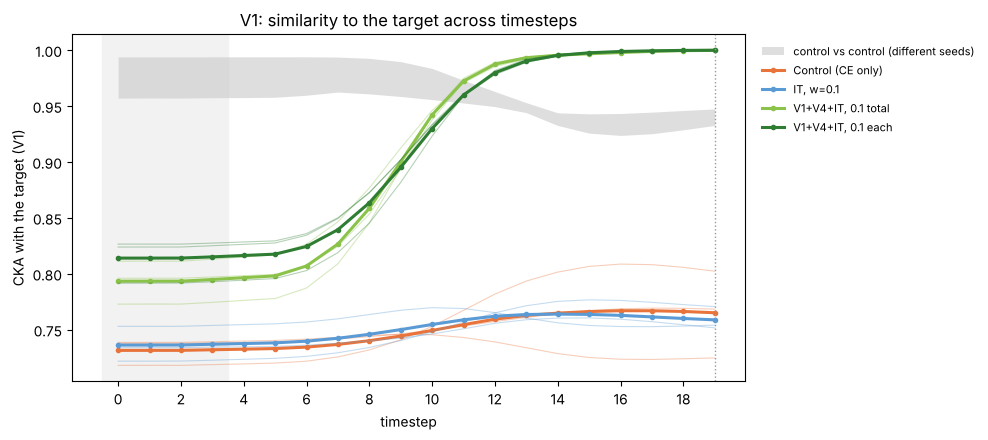

In [8]:
LAYER = "V1"
CONDITIONS = ["control", "IT_w0p1", "V1V4IT_total0p1", "V1V4IT_w0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.axvline(LAST_T, color="#999999", lw=1, ls=":")
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER}: similarity to the target across timesteps")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, f"fig2_1_{LAYER}_cka_by_timestep")
plt.show()

Findings: _to be written._

### Figure 2.2 — V4: similarity to the target at each timestep (test set)

- **Question**: how close is each student's V4 to the target's V4, and at which timesteps?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "V4"` — `cka` vs `timestep`. Grey band: `comparison == "control_vs_control"` (range over the 3 pairs of control seeds).
- **How to read**: the alignment terms act at t19 (dotted line); a gap at earlier timesteps means the alignment spread through the dynamics. Values above the grey band: the student is closer to the target than two independently seeded controls are to each other.

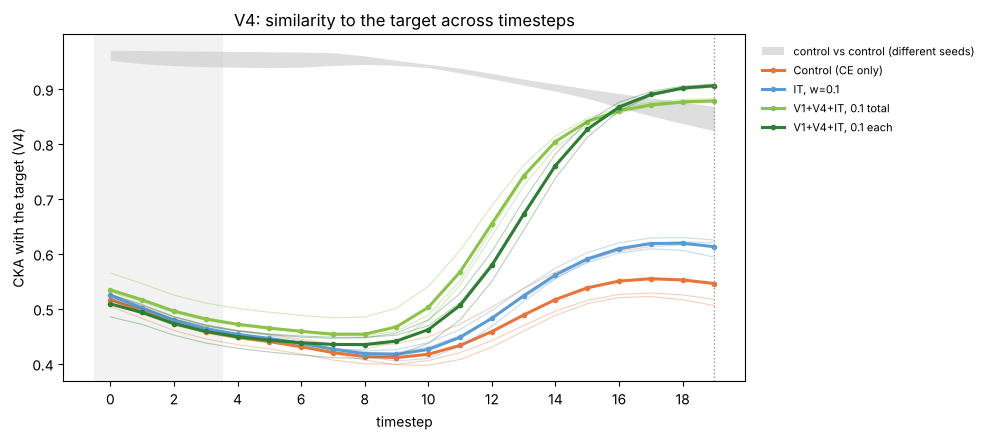

In [9]:
LAYER = "V4"
CONDITIONS = ["control", "IT_w0p1", "V1V4IT_total0p1", "V1V4IT_w0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.axvline(LAST_T, color="#999999", lw=1, ls=":")
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER}: similarity to the target across timesteps")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, f"fig2_2_{LAYER}_cka_by_timestep")
plt.show()

Findings: _to be written._

### Figure 2.3 — IT: similarity to the target at each timestep (test set)

- **Question**: how close is each student's IT to the target's IT, and at which timesteps?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "IT"` — `cka` vs `timestep`. Grey band: `comparison == "control_vs_control"` (range over the 3 pairs of control seeds).
- **How to read**: the alignment terms act at t19 (dotted line); a gap at earlier timesteps means the alignment spread through the dynamics. Values above the grey band: the student is closer to the target than two independently seeded controls are to each other.

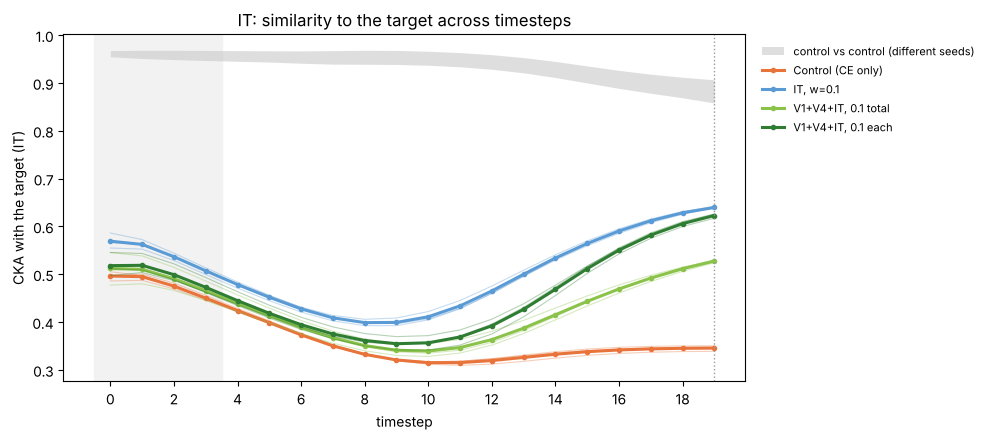

In [10]:
LAYER = "IT"
CONDITIONS = ["control", "IT_w0p1", "V1V4IT_total0p1", "V1V4IT_w0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.axvline(LAST_T, color="#999999", lw=1, ls=":")
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER}: similarity to the target across timesteps")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, f"fig2_3_{LAYER}_cka_by_timestep")
plt.show()

Findings: _to be written._

## 3 — Which timesteps are aligned

Conditions compared: control, **IT at t19** (w=0.1), **IT at t2, t6, t12 and t19** (0.025 each, same total weight 0.1). The two aligned conditions differ only in *when* the alignment is applied.

### Figure 3.1 — IT: similarity to the target at each timestep (test set)

- **Question**: does aligning IT at several timesteps keep it close to the target throughout the dynamics, compared with aligning it only at the end?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "IT"` — `cka` vs `timestep`. Purple dotted lines: the four aligned timesteps (t19 is also the only one for "IT, w=0.1"). Grey band: control vs control.
- **How to read**: compare the two aligned conditions between the aligned timesteps — does the multi-timestep student stay high in between, or only at the four constrained points?

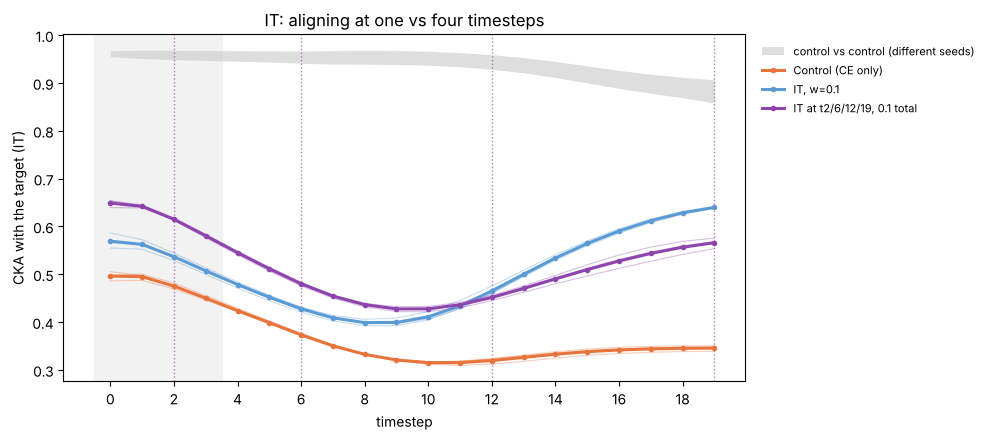

In [11]:
LAYER = "IT"
CONDITIONS = ["control", "IT_w0p1", "IT_multiT_total0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for t in D_TIMESTEPS:
    ax.axvline(t, color=COLORS["IT_multiT_total0p1"], lw=1, ls=":", alpha=0.7)
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel("CKA with the target (IT)")
ax.set_title("IT: aligning at one vs four timesteps")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "fig3_1_IT_cka_one_vs_four_timesteps")
plt.show()

Findings: _to be written._

### Figure 3.2 — Where in time each condition's alignment lands (IT, heatmap)

- **Question**: for every condition at once — at which timesteps did IT move toward the target?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "IT"` — each cell: CKA of the condition minus CKA of the control of the same seed, averaged over the 3 seeds. Rows = conditions, columns = timesteps. Black boxes: the timesteps where IT is in that condition's loss.
- **How to read**: red = closer to the target than the control, blue = further away, white = no difference.

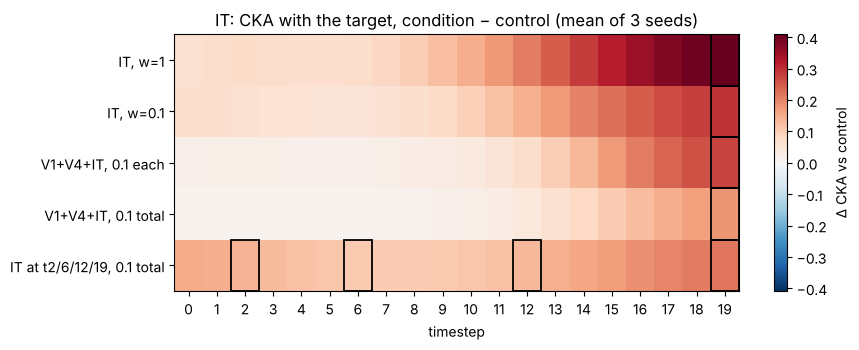

In [12]:
LAYER = "IT"
CONDITIONS = ["IT_w1", "IT_w0p1", "V1V4IT_w0p1", "V1V4IT_total0p1", "IT_multiT_total0p1"]
ALIGNED_TIMESTEPS = {"IT_w1": [19], "IT_w0p1": [19], "V1V4IT_w0p1": [19], "V1V4IT_total0p1": [19],
                     "IT_multiT_total0p1": D_TIMESTEPS}

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
control = d[d["condition"] == "control"].set_index(["seed", "timestep"])["cka"]
M = np.full((len(CONDITIONS), T), np.nan)
for i, cond in enumerate(CONDITIONS):
    delta = d[d["condition"] == cond].set_index(["seed", "timestep"])["cka"] - control
    mean = delta.groupby(level="timestep").mean()
    M[i, mean.index.astype(int)] = mean.values
lim = np.nanmax(np.abs(M))

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(M, aspect="auto", cmap="RdBu_r", norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim))
for i, cond in enumerate(CONDITIONS):
    for t in ALIGNED_TIMESTEPS[cond]:
        ax.add_patch(Rectangle((t - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="black", lw=1.3))
ax.set_yticks(range(len(CONDITIONS)))
ax.set_yticklabels([LABELS[c] for c in CONDITIONS])
ax.set_xticks(range(T))
ax.set_xlabel("timestep")
ax.set_title("IT: CKA with the target, condition − control (mean of 3 seeds)")
fig.colorbar(im, ax=ax, label="Δ CKA vs control")
plt.tight_layout()
save(fig, "fig3_2_heatmap_delta_IT_cka")
plt.show()

$$
\Delta_{c,t} \;=\; \frac{1}{3}\sum_{s \in \{2723,\,2724,\,2725\}} \Big[\, \mathrm{CKA}\big(\mathrm{IT}^{c,s}_t,\ \mathrm{IT}^{\mathrm{target}}_t\big) \;-\; \mathrm{CKA}\big(\mathrm{IT}^{\mathrm{control},s}_t,\ \mathrm{IT}^{\mathrm{target}}_t\big) \Big]
$$

where $c$ is the condition, $t$ the timestep and $s$ the seed; $\mathrm{IT}^{c,s}_t$ is the IT activity at timestep $t$ of the student of condition $c$ trained with seed $s$, over all test images.

### Figure 3.3 — The impact on V1, V4, when aligning multiple timesteps on IT

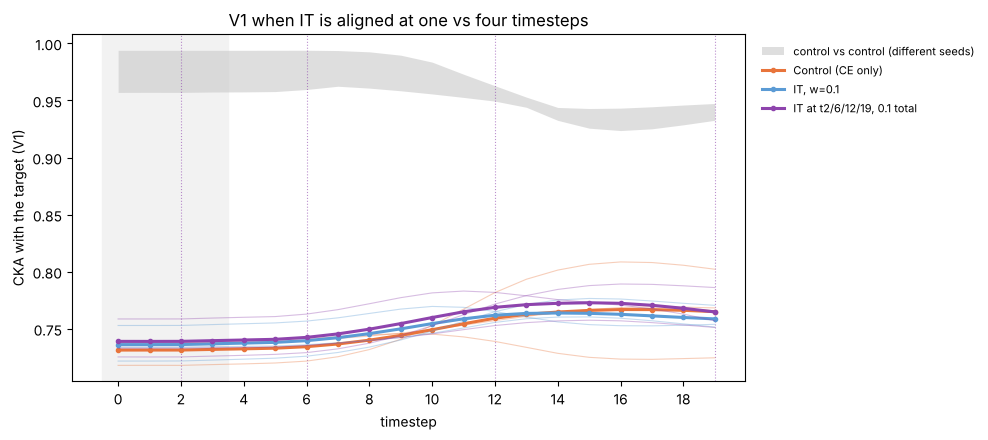

In [13]:
LAYER = "V1"
CONDITIONS = ["control", "IT_w0p1", "IT_multiT_total0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for t in D_TIMESTEPS:
    ax.axvline(t, color=COLORS["IT_multiT_total0p1"], lw=0.8, ls=":", alpha=0.6)
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER} when IT is aligned at one vs four timesteps")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, f"fig3_3a_{LAYER}_IT_one_vs_four_timesteps")
plt.show()

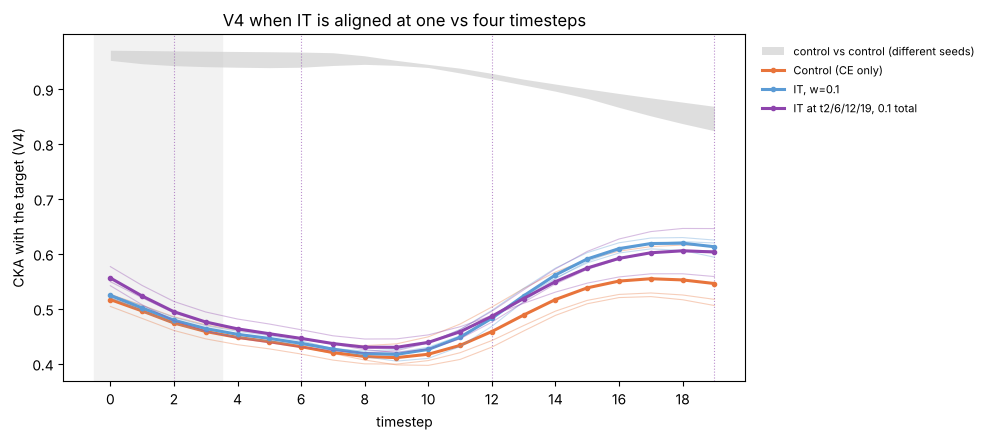

In [14]:
LAYER = "V4"
CONDITIONS = ["control", "IT_w0p1", "IT_multiT_total0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for t in D_TIMESTEPS:
    ax.axvline(t, color=COLORS["IT_multiT_total0p1"], lw=0.8, ls=":", alpha=0.6)
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER} when IT is aligned at one vs four timesteps")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, f"fig3_3b_{LAYER}_IT_one_vs_four_timesteps")
plt.show()

## 4 — How strongly to align

Conditions compared: IT with weight 1 vs 0.1; V1+V4+IT with 0.1 each vs 0.1 in total.

### Figure 4.1 — Alignment vs recognition: is there a cost?

- **Question**: do the students that are most aligned with the target pay for it in accuracy?
- **Plotted**: `summary.csv` (test set, t19) — x: `cka_IT`, y: `accuracy`. Small dots = seeds, large dots = mean of each condition. Dashed line: the target's accuracy.
- **How to read**: points further right are more aligned; points lower are less accurate. A cost would show as a downward trend from left to right.

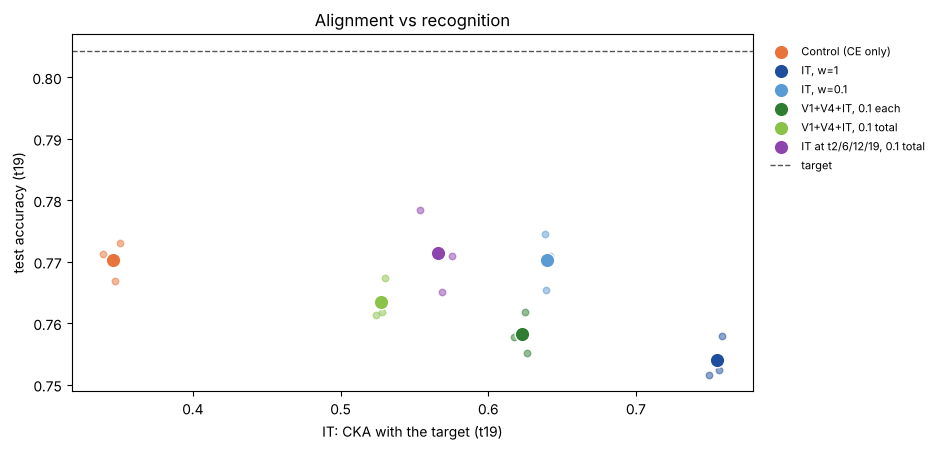

In [15]:
CONDITIONS = ORDER
X, Y = "cka_IT", "accuracy"

s = summary
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for cond in CONDITIONS:
    sc = s[s["condition"] == cond]
    ax.scatter(sc[X], sc[Y], color=COLORS[cond], s=22, alpha=0.5)
    ax.scatter([sc[X].mean()], [sc[Y].mean()], color=COLORS[cond], s=110, edgecolor="white", lw=1, label=LABELS[cond])
tgt = s.loc[s["condition"] == "target", Y]
if len(tgt):
    ax.axhline(tgt.iloc[0], color=TARGET_COLOR, lw=1, ls="--", label="target")
ax.set_xlabel("IT: CKA with the target (t19)")
ax.set_ylabel("test accuracy (t19)")
ax.set_title("Alignment vs recognition")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "fig4_1_alignment_vs_accuracy")
plt.show()

Findings: _to be written._

### Figure 4.2 — During training: loss on the target's answers (IT weight 1 vs 0.1)

- **Question**: does a stronger alignment slow down or limit learning the target's answers?
- **Plotted**: `student_training.csv` — `val_ce` (cross-entropy vs the target's final answer, validation set, averaged over timesteps 4–19) vs `epochs_completed`.

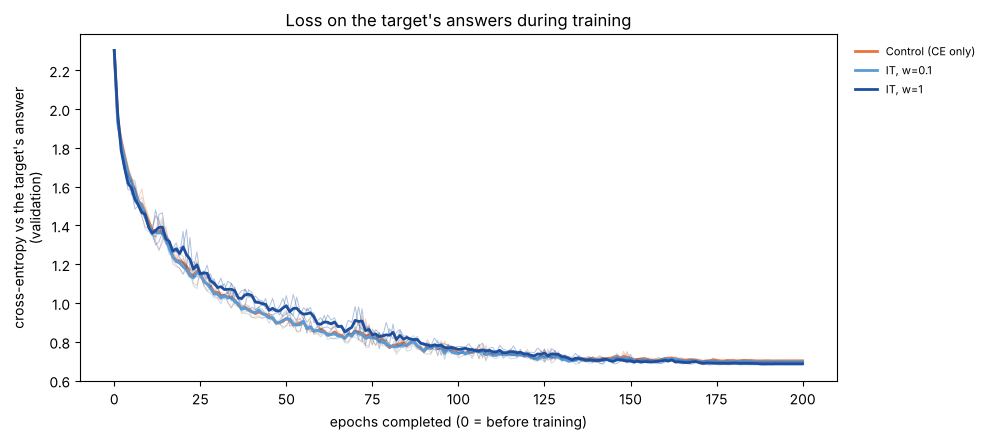

In [16]:
CONDITIONS = ["control", "IT_w0p1", "IT_w1"]

d = student_training
fig, ax = plt.subplots(figsize=(10, 4.5))
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["epochs_completed"], ds["val_ce"], color=COLORS[cond], lw=0.7, alpha=0.35)
    mean = dc.groupby("epochs_completed")["val_ce"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2, label=LABELS[cond])
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("cross-entropy vs the target's answer\n(validation)")
ax.set_title("Loss on the target's answers during training")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "fig4_2_val_ce")
plt.show()

### Figure 4.3 — During training: loss on the target's answers (V1+V4+IT, 0.1 total vs 0.1 each)

- **Question**: does a stronger alignment slow down or limit learning the target's answers?
- **Plotted**: `student_training.csv` — `val_ce` (cross-entropy vs the target's final answer, validation set, averaged over timesteps 4–19) vs `epochs_completed`.

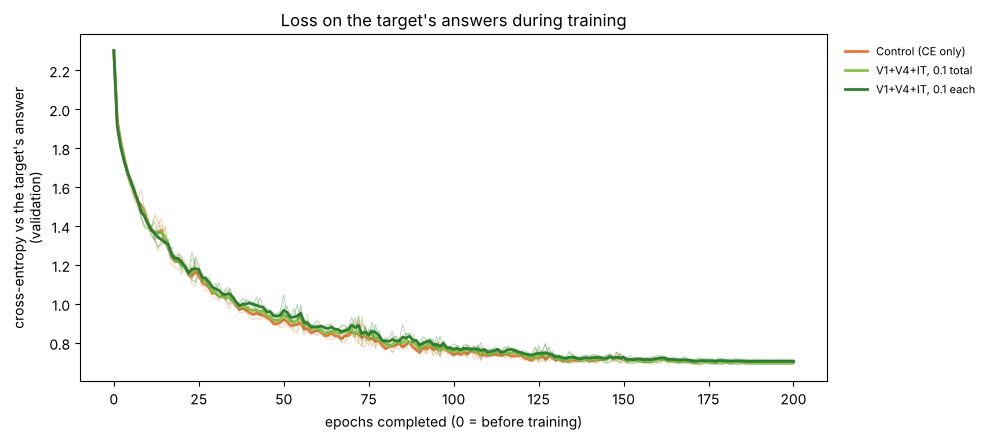

In [17]:
CONDITIONS = ["control", "V1V4IT_total0p1", "V1V4IT_w0p1"]

d = student_training
fig, ax = plt.subplots(figsize=(10, 4.5))
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["epochs_completed"], ds["val_ce"], color=COLORS[cond], lw=0.7, alpha=0.35)
    mean = dc.groupby("epochs_completed")["val_ce"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2, label=LABELS[cond])
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("cross-entropy vs the target's answer\n(validation)")
ax.set_title("Loss on the target's answers during training")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "fig4_3_val_ce")
plt.show()

## 5 — Round 3 vs round 4

The students and their training are identical in the two rounds; only the target differs (round 3: DyRCNNx4, the students' own architecture; round 4: DyRCNNx8, feedback off). Every comparison below is between a round 4 student and its round 3 twin (same condition, same seed).

Marker / line style = round (round 3: hollow squares, dashed; round 4: filled circles, solid); color = condition, as everywhere else. All values: test set.

### Table 5.1 — Both rounds side by side (timestep 19)

Mean over the 3 seeds. Columns: round 3 | round 4 for each measure; the last row is the target.

In [18]:
cols = ["accuracy", "same_answer_as_target", "ce_vs_target_answer", "cka_V1", "cka_V4", "cka_IT"]
parts = {}
for rnd, r in ROUNDS.items():
    s = r["summary"]
    m = s[s["condition"] != "target"].groupby("condition")[cols].mean().reindex(ORDER)
    m.loc["target", "accuracy"] = s.loc[s["condition"] == "target", "accuracy"].iloc[0]
    parts[rnd] = m
table = pd.concat(parts, axis=1).swaplevel(axis=1)[cols]
table.index = [LABELS.get(c, "Target") for c in table.index]
table.round(3)

accuracy         same_answer_as_target          \
                             round 3 round 4               round 3 round 4   
Control (CE only)              0.763   0.770                 0.856   0.794   
IT, w=1                        0.764   0.754                 0.885   0.785   
IT, w=0.1                      0.772   0.770                 0.893   0.801   
V1+V4+IT, 0.1 each             0.769   0.758                 0.898   0.795   
V1+V4+IT, 0.1 total            0.769   0.763                 0.890   0.798   
IT at t2/6/12/19, 0.1 total    0.770   0.771                 0.887   0.799   
Target                         0.785   0.804                   NaN     NaN   

                            ce_vs_target_answer          cka_V1          \
                                        round 3 round 4 round 3 round 4   
Control (CE only)                         0.459   0.743   0.958   0.765   
IT, w=1                                   0.313   0.665   0.957   0.798   
IT, w=0.1                                 0.321   0.714   0.922   0.759   
V1+V4+IT, 0.1 each                        0.281   0.677   1.000   1.000   
V1+V4+IT, 0.1 total                       0.317   0.701   1.000   1.000   
IT at t2/6/12/19, 0.1 total               0.353   0.748   0.957   0.765   
Target                                      NaN     NaN     NaN     NaN   

                             cka_V4          cka_IT          
                            round 3 round 4 round 3 round 4  
Control (CE only)             0.835   0.546   0.843   0.346  
IT, w=1                       0.931   0.605   0.987   0.755  
IT, w=0.1                     0.948   0.613   0.977   0.640  
V1+V4+IT, 0.1 each            0.994   0.906   0.983   0.623  
V1+V4+IT, 0.1 total           0.990   0.878   0.970   0.528  
IT at t2/6/12/19, 0.1 total   0.951   0.603   0.968   0.566  
Target                          NaN     NaN     NaN     NaN

Findings: _to be written._

### Figure 5.2 — IT: similarity to the target at t19, round 3 vs round 4

- **Question**: how close can each condition bring IT to the target when the target's architecture differs?
- **Plotted**: `summary.csv` of both rounds — `cka_IT` per condition. Small markers = seeds, large markers = mean.
- **How to read**: the control shows how similar a student is to the target without any alignment; the distance between the control and the aligned conditions is what the alignment achieved.

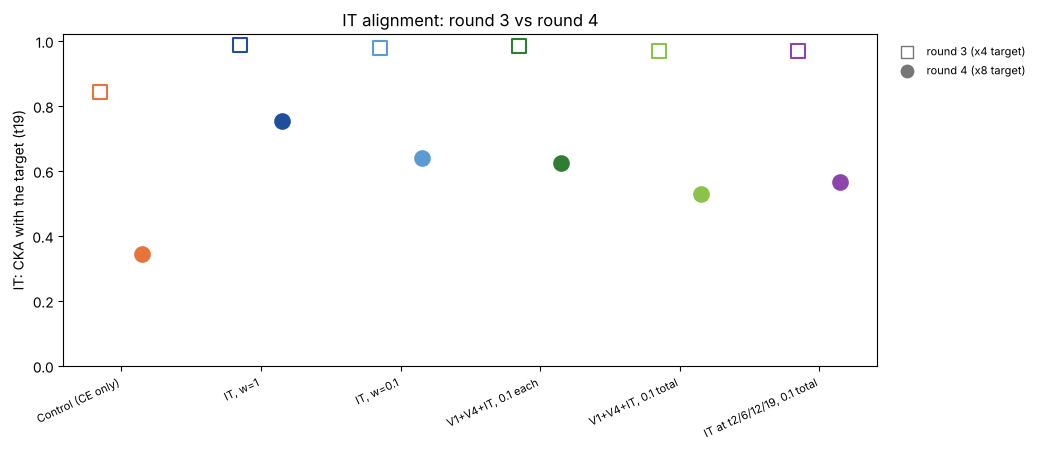

In [19]:
X = np.arange(len(ORDER))
fig, ax = plt.subplots(figsize=(10.5, 4.6))
for k, (rnd, r) in enumerate(ROUNDS.items()):
    st_ = ROUND_STYLE[rnd]
    s = r["summary"]
    for j, cond in enumerate(ORDER):
        v = s.loc[s["condition"] == cond, "cka_IT"]
        x = X[j] + (k - 0.5) * 0.3
        face = COLORS[cond] if st_["filled"] else "white"
        ax.scatter(np.full(len(v), x), v, marker=st_["marker"], s=18, facecolor=face, edgecolor=COLORS[cond], alpha=0.5)
        ax.scatter([x], [v.mean()], marker=st_["marker"], s=110, facecolor=face, edgecolor=COLORS[cond], lw=1.5)
for rnd, st_ in ROUND_STYLE.items():
    ax.scatter([], [], marker=st_["marker"], s=80, facecolor="#777777" if st_["filled"] else "white",
               edgecolor="#777777", label=st_["label"])
ax.set_xticks(X)
ax.set_xticklabels([LABELS[c] for c in ORDER], rotation=25, ha="right", fontsize=8)
ax.set_ylim(0, 1.02)
ax.set_ylabel("IT: CKA with the target (t19)")
ax.set_title("IT alignment: round 3 vs round 4")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "fig5_2_IT_cka_round3_vs_round4")
plt.show()

Findings: _to be written._

### Figure 5.3 — What the alignment added: IT CKA minus the control's, round 3 vs round 4

- **Question**: is the effect of the alignment itself (not the starting similarity) as large with an x8 target as with an x4 target?
- **Plotted**: `summary.csv` of both rounds — for every aligned student, `cka_IT` minus `cka_IT` of the control of the **same seed** (t19). Small markers = seeds, large markers = mean.
- **How to read**: 0 (dashed) = no gain over the control. The gain is limited by how far the control starts from 1, so the two rounds have different ceilings (round 3 control ≈ 0.84, round 4 ≈ 0.35).

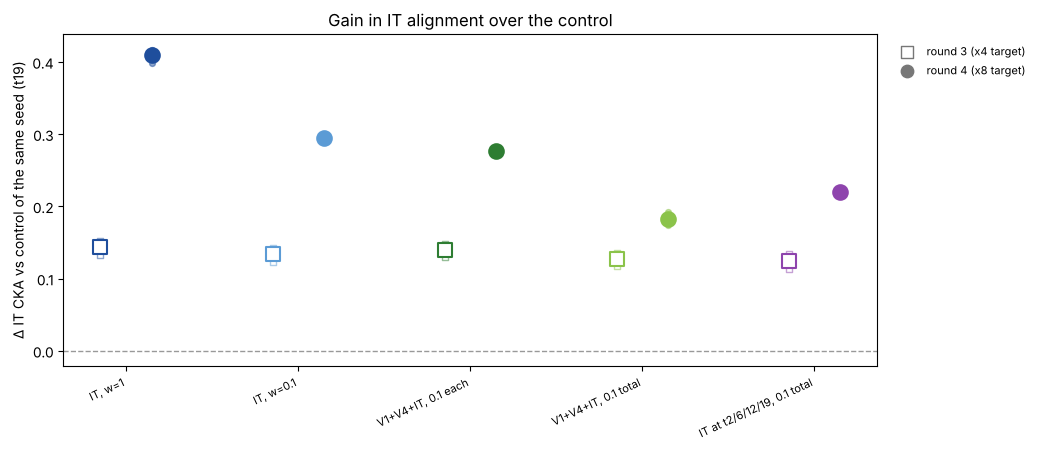

In [20]:
CONDITIONS = [c for c in ORDER if c != "control"]
X = np.arange(len(CONDITIONS))
fig, ax = plt.subplots(figsize=(10.5, 4.6))
for k, (rnd, r) in enumerate(ROUNDS.items()):
    st_ = ROUND_STYLE[rnd]
    s = r["summary"]
    ctrl = s[s["condition"] == "control"].set_index("seed")["cka_IT"]
    for j, cond in enumerate(CONDITIONS):
        v = s[s["condition"] == cond].set_index("seed")["cka_IT"] - ctrl
        x = X[j] + (k - 0.5) * 0.3
        face = COLORS[cond] if st_["filled"] else "white"
        ax.scatter(np.full(len(v), x), v, marker=st_["marker"], s=18, facecolor=face, edgecolor=COLORS[cond], alpha=0.5)
        ax.scatter([x], [v.mean()], marker=st_["marker"], s=110, facecolor=face, edgecolor=COLORS[cond], lw=1.5)
for rnd, st_ in ROUND_STYLE.items():
    ax.scatter([], [], marker=st_["marker"], s=80, facecolor="#777777" if st_["filled"] else "white",
               edgecolor="#777777", label=st_["label"])
ax.axhline(0, color="#999999", lw=1, ls="--")
ax.set_xticks(X)
ax.set_xticklabels([LABELS[c] for c in CONDITIONS], rotation=25, ha="right", fontsize=8)
ax.set_ylabel("Δ IT CKA vs control of the same seed (t19)")
ax.set_title("Gain in IT alignment over the control")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "fig5_3_IT_cka_gain_round3_vs_round4")
plt.show()

Findings: _to be written._

### Figure 5.4 — Cost or gain in accuracy relative to the control, round 3 vs round 4

- **Question**: does aligning to a target of a different architecture cost recognition accuracy?
- **Plotted**: `summary.csv` of both rounds — for every aligned student, test `accuracy` minus the accuracy of the control of the **same seed** (t19). Small markers = seeds, large markers = mean.
- **How to read**: above 0 (dashed) = the aligned student recognizes better than its control; below 0 = alignment costs accuracy.

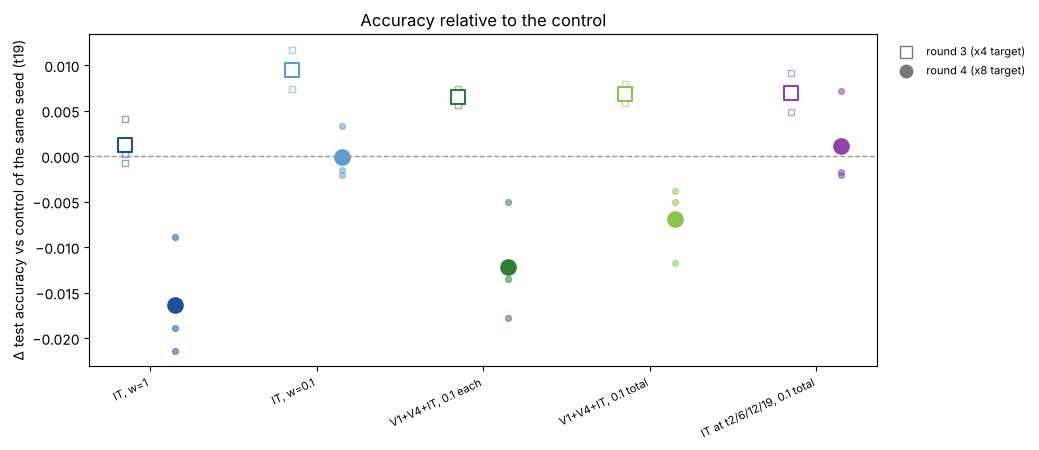

In [21]:
CONDITIONS = [c for c in ORDER if c != "control"]
X = np.arange(len(CONDITIONS))
fig, ax = plt.subplots(figsize=(10.5, 4.6))
for k, (rnd, r) in enumerate(ROUNDS.items()):
    st_ = ROUND_STYLE[rnd]
    s = r["summary"]
    ctrl = s[s["condition"] == "control"].set_index("seed")["accuracy"]
    for j, cond in enumerate(CONDITIONS):
        v = s[s["condition"] == cond].set_index("seed")["accuracy"] - ctrl
        x = X[j] + (k - 0.5) * 0.3
        face = COLORS[cond] if st_["filled"] else "white"
        ax.scatter(np.full(len(v), x), v, marker=st_["marker"], s=18, facecolor=face, edgecolor=COLORS[cond], alpha=0.5)
        ax.scatter([x], [v.mean()], marker=st_["marker"], s=110, facecolor=face, edgecolor=COLORS[cond], lw=1.5)
for rnd, st_ in ROUND_STYLE.items():
    ax.scatter([], [], marker=st_["marker"], s=80, facecolor="#777777" if st_["filled"] else "white",
               edgecolor="#777777", label=st_["label"])
ax.axhline(0, color="#999999", lw=1, ls="--")
ax.set_xticks(X)
ax.set_xticklabels([LABELS[c] for c in CONDITIONS], rotation=25, ha="right", fontsize=8)
ax.set_ylabel("Δ test accuracy vs control of the same seed (t19)")
ax.set_title("Accuracy relative to the control")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "fig5_4_accuracy_vs_control_round3_vs_round4")
plt.show()

Findings: _to be written._

### Figure 5.5 — IT: similarity to the target at each timestep, round 3 vs round 4

- **Question**: at which timesteps does the x8 target become harder to match than the x4 target?
- **Plotted**: `test_cka.csv` of both rounds, `comparison == "student_vs_target"`, `layer == "IT"` — `cka` vs `timestep` for the control and IT, w=0.1. Solid = round 4, dashed = round 3.
- **How to read**: the gap between a dashed and a solid line of the same color is the effect of changing the target, for the same students.

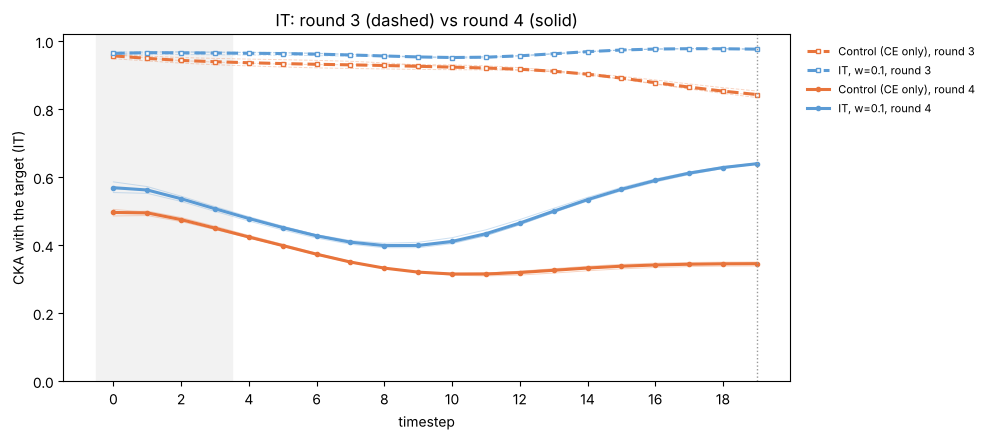

In [22]:
LAYER = "IT"
CONDITIONS = ["control", "IT_w0p1"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
for rnd, r in ROUNDS.items():
    st_ = ROUND_STYLE[rnd]
    c = r["test_cka"]
    d = c[(c["comparison"] == "student_vs_target") & (c["layer"] == LAYER)]
    for cond in CONDITIONS:
        dc = d[d["condition"] == cond]
        for seed, ds in dc.groupby("seed"):
            ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.7, ls=st_["ls"], alpha=0.3)
        mean = dc.groupby("timestep")["cka"].mean()
        ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, ls=st_["ls"], marker=st_["marker"], ms=3,
                mfc=COLORS[cond] if st_["filled"] else "white", label=f"{LABELS[cond]}, {rnd}")
ax.axvline(LAST_T, color="#999999", lw=1, ls=":")
ax.set_xticks(range(0, T, 2))
ax.set_ylim(0, 1.02)
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER}: round 3 (dashed) vs round 4 (solid)")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "fig5_5_IT_cka_by_timestep_round3_vs_round4")
plt.show()

Findings: _to be written._

## Appendix — Training details

Checks that training behaved as intended. Not needed to follow the results above.

### Figure A.1 — Loss on the target's answers (control, IT at t19, IT at four timesteps)

Same as Figures 4.2 / 4.3 for the conditions of section 3. Source: `student_training.csv`, `val_ce`.

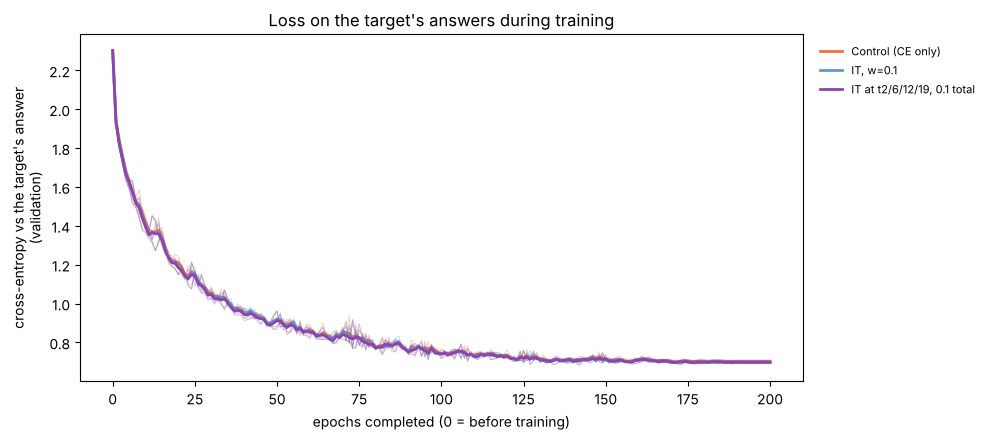

In [23]:
CONDITIONS = ["control", "IT_w0p1", "IT_multiT_total0p1"]

d = student_training
fig, ax = plt.subplots(figsize=(10, 4.5))
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["epochs_completed"], ds["val_ce"], color=COLORS[cond], lw=0.7, alpha=0.35)
    mean = dc.groupby("epochs_completed")["val_ce"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2, label=LABELS[cond])
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("cross-entropy vs the target's answer\n(validation)")
ax.set_title("Loss on the target's answers during training")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "figA_1_val_ce")
plt.show()

### Figure A.2 — IT similarity to the target during training (t19)

- **Plotted**: `student_training.csv` — `val_cka_IT_t19` (batch CKA, validation) vs `epochs_completed`, all conditions, mean over seeds only.
- **How to read**: how quickly each condition aligns IT. At epoch 0 all students of one seed are identical, so the curves start from the same point.

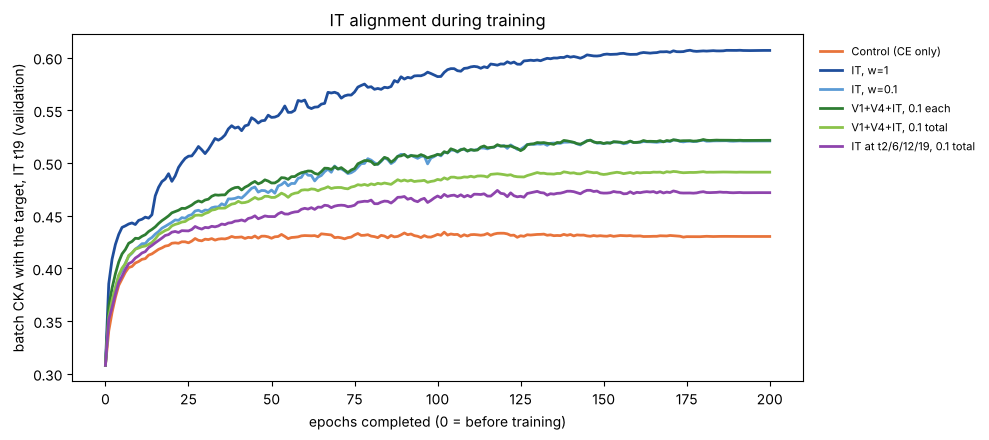

In [24]:
CONDITIONS = ORDER
COLUMN = "val_cka_IT_t19"

d = student_training
fig, ax = plt.subplots(figsize=(10, 4.5))
for cond in CONDITIONS:
    mean = d[d["condition"] == cond].groupby("epochs_completed")[COLUMN].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2, label=LABELS[cond])
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("batch CKA with the target, IT t19 (validation)")
ax.set_title("IT alignment during training")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "figA_2_training_IT_cka")
plt.show()

### Figure A.3 — Balance between the alignment terms and the CE term

- **Plotted**: `student_training.csv` — `grad_ratio_cka_to_ce` vs `epochs_completed` (log scale), aligned conditions, mean over seeds.
- **How to read**: above 1 (dashed) = the alignment terms dominate the parameter update. The gradient of log(1 − CKA) grows like weight / (1 − CKA), so the ratio tends to rise as CKA approaches 1.

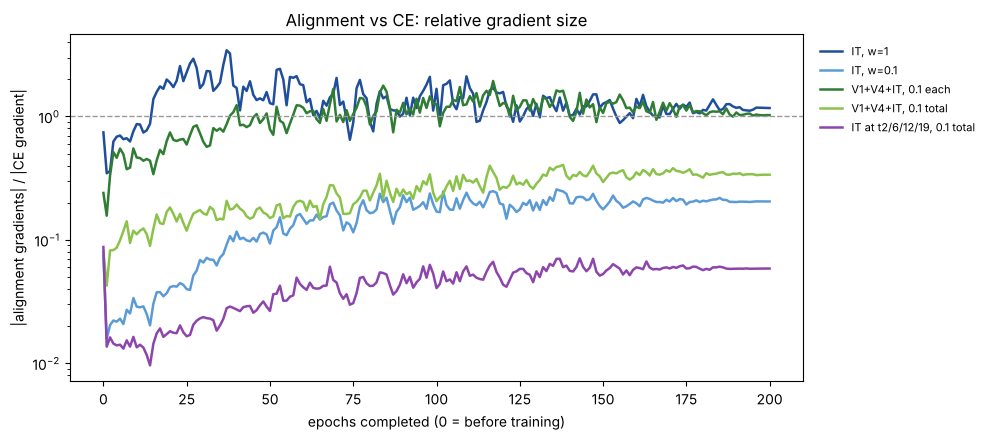

In [25]:
CONDITIONS = [c for c in ORDER if c != "control"]
COLUMN = "grad_ratio_cka_to_ce"

d = student_training
fig, ax = plt.subplots(figsize=(10, 4.5))
for cond in CONDITIONS:
    mean = d[d["condition"] == cond].groupby("epochs_completed")[COLUMN].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=1.8, label=LABELS[cond])
ax.axhline(1, color="#999999", lw=1, ls="--")
ax.set_yscale("log")
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("|alignment gradients| / |CE gradient|")
ax.set_title("Alignment vs CE: relative gradient size")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "figA_3_gradient_ratio")
plt.show()

### Figure A.4 — Gradient size per training step

- **Plotted**: `student_training.csv` — `train_grad_norm` (mean over the steps of each epoch, before clipping) vs `epochs_completed`, mean over seeds. Dashed: the clipping threshold (500).
- **How to read**: all curves far below the threshold = clipping never changed an update (also see `train_clip_fraction`).

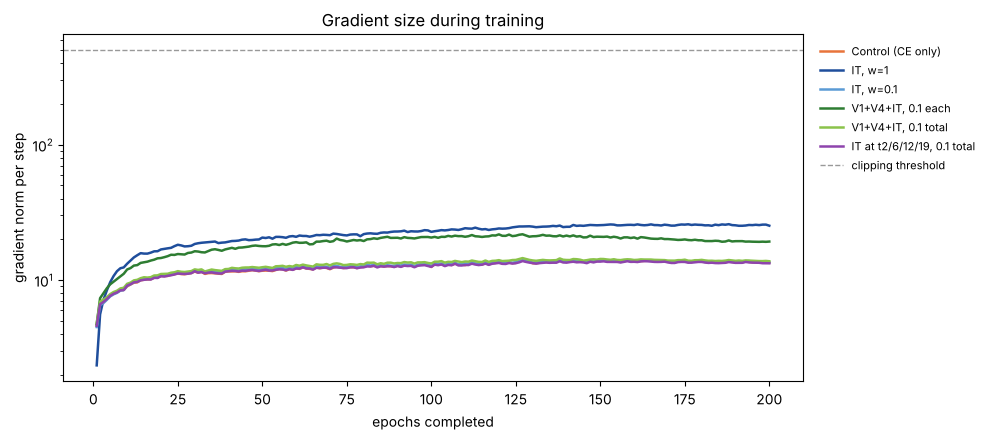

largest fraction of clipped steps in any epoch of any run: 0.0


In [26]:
CONDITIONS = ORDER
COLUMN = "train_grad_norm"
CLIP_THRESHOLD = 500

d = student_training
fig, ax = plt.subplots(figsize=(10, 4.5))
for cond in CONDITIONS:
    mean = d[d["condition"] == cond].groupby("epochs_completed")[COLUMN].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=1.8, label=LABELS[cond])
ax.axhline(CLIP_THRESHOLD, color="#999999", lw=1, ls="--", label="clipping threshold")
ax.set_yscale("log")
ax.set_xlabel("epochs completed")
ax.set_ylabel("gradient norm per step")
ax.set_title("Gradient size during training")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
save(fig, "figA_4_gradient_norm")
plt.show()
print("largest fraction of clipped steps in any epoch of any run:", d["train_clip_fraction"].max())